# Kenya Tourism Analysis, 1995–2025
Analysis of international visitor arrivals and tourism earnings in Kenya using World Bank and KNBS data.

**Sources**
- World Bank WDI: `ST.INT.ARVL` (arrivals) and `ST.INT.RCPT.CD` (receipts, US$). Kenya data ends in 2019.
- KNBS *Economic Survey 2026*, Chapter 12 (Tourism) and Table 6.16 / 6.19 (balance of payments, exchange rates).
- KNBS *Leading Economic Indicators, March 2026*, Table 18 (monthly arrivals, Jan–Mar 2026).

**Caveat:** World Bank and KNBS arrivals are different series (they do not match in 2015–2019), so they are plotted separately and never joined.

## 1. Load the data
If the `data/` folder is missing (e.g. in Colab), upload the four CSV files when prompted.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

os.makedirs("charts", exist_ok=True)
files = ["arrivals.csv", "earnings.csv", "visitors_by_purpose.csv", "monthly_arrivals.csv"]
if not all(os.path.exists(f"data/{f}") for f in files):
    from google.colab import files as colab_files
    os.makedirs("data", exist_ok=True)
    for name, content in colab_files.upload().items():
        open(f"data/{name}", "wb").write(content)

arrivals = pd.read_csv("data/arrivals.csv")
earnings = pd.read_csv("data/earnings.csv")
purpose  = pd.read_csv("data/visitors_by_purpose.csv")
monthly  = pd.read_csv("data/monthly_arrivals.csv")
for name, df in [("arrivals", arrivals), ("earnings", earnings), ("purpose", purpose), ("monthly", monthly)]:
    print(name, df.shape)
arrivals.tail()

arrivals (31, 3)
earnings (31, 5)
purpose (275, 4)
monthly (39, 7)


,year,wb_arrivals,knbs_arrivals
26,2021,NaN,871300.0
27,2022,NaN,1541000.0
28,2023,NaN,2096004.0
29,2024,NaN,2401256.0
30,2025,NaN,2550641.0


## 2. Check and clean
Columns are already tidy. We check types, duplicates and missing values. Blanks are expected (World Bank stops in 2019; KNBS starts in 2015) and are **kept as missing, not filled**.

In [2]:
for name, df in [("arrivals", arrivals), ("earnings", earnings), ("purpose", purpose), ("monthly", monthly)]:
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
    print(name, "| duplicates:", df.duplicated().sum(), "| missing:", df.isnull().sum().to_dict())

# Derived columns used in the charts
arrivals["knbs_yoy_pct"] = arrivals["knbs_arrivals"].pct_change(fill_method=None) * 100
earnings["wb_receipts_usd_bn"] = earnings["wb_receipts_usd"] / 1e9
earnings["bop_travel_usd_bn"] = earnings["bop_travel_receipts_usd_million_derived"] / 1e3

arrivals | duplicates: 0 | missing: {'year': 0, 'wb_arrivals': 6, 'knbs_arrivals': 20}
earnings | duplicates: 0 | missing: {'year': 0, 'wb_receipts_usd': 6, 'bop_travel_receipts_ksh_million': 26, 'avg_exchange_rate_ksh_per_usd': 26, 'bop_travel_receipts_usd_million_derived': 26}
purpose | duplicates: 0 | missing: {'year': 0, 'period': 0, 'purpose': 0, 'arrivals_thousand': 0}
monthly | duplicates: 0 | missing: {'year': 0, 'month': 0, 'mia': 0, 'jkia': 0, 'other_borders': 0, 'total': 0, 'status': 0}


## 3. Charts

In [3]:
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c3",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "figure.dpi": 100})

def save(name):
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

### Chart 1: Arrivals trend (`arrivals_trend.png`)

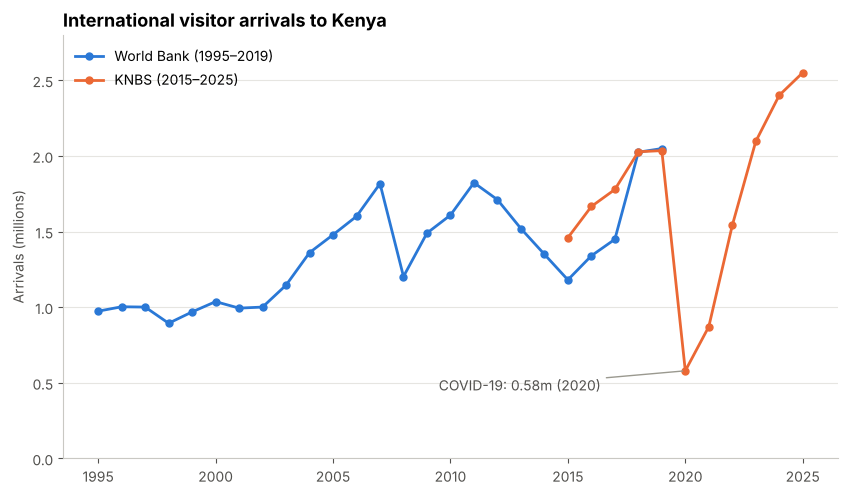

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
wb = arrivals.dropna(subset=["wb_arrivals"]); kn = arrivals.dropna(subset=["knbs_arrivals"])
ax.plot(wb["year"], wb["wb_arrivals"]/1e6, color=BLUE, lw=2, marker="o", ms=5, label="World Bank (1995–2019)")
ax.plot(kn["year"], kn["knbs_arrivals"]/1e6, color=ORANGE, lw=2, marker="o", ms=5, label="KNBS (2015–2025)")
ax.annotate("COVID-19: 0.58m (2020)", (2020, 0.5796), xytext=(2009.5, 0.45), color=MUTED,
            arrowprops=dict(arrowstyle="-", color="#9a998f"))
ax.set_title("International visitor arrivals to Kenya")
ax.set_ylabel("Arrivals (millions)"); ax.set_ylim(0, 2.8); ax.legend(frameon=False, loc="upper left")
save("arrivals_trend")

### Chart 2: Tourism earnings (`earnings_trend.png`)

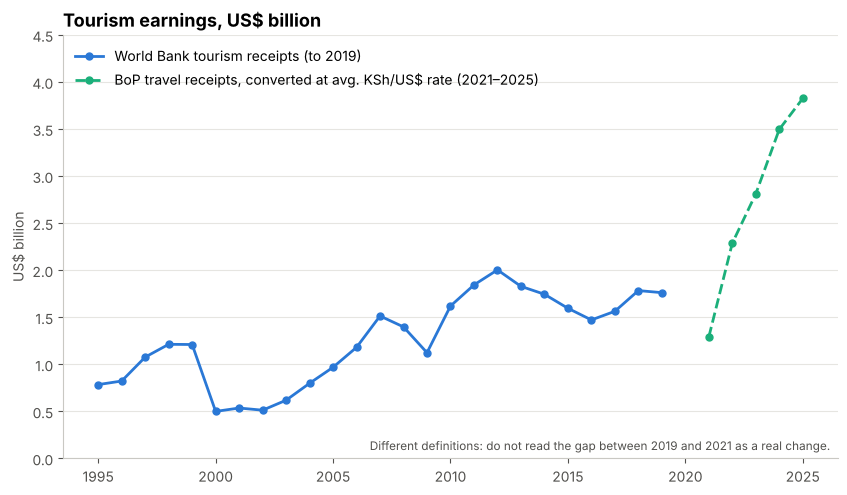

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
w = earnings.dropna(subset=["wb_receipts_usd_bn"]); b = earnings.dropna(subset=["bop_travel_usd_bn"])
ax.plot(w["year"], w["wb_receipts_usd_bn"], color=BLUE, lw=2, marker="o", ms=5, label="World Bank tourism receipts (to 2019)")
ax.plot(b["year"], b["bop_travel_usd_bn"], color=AQUA, lw=2, ls="--", marker="o", ms=5,
        label="BoP travel receipts, converted at avg. KSh/US$ rate (2021–2025)")
ax.set_title("Tourism earnings, US$ billion")
ax.set_ylabel("US$ billion"); ax.set_ylim(0, 4.5); ax.legend(frameon=False, loc="upper left")
ax.text(0.99, 0.02, "Different definitions: do not read the gap between 2019 and 2021 as a real change.",
        transform=ax.transAxes, ha="right", fontsize=8.5, color=MUTED)
save("earnings_trend")

### Chart 3: Arrivals vs earnings (`arrivals_vs_earnings.png`)

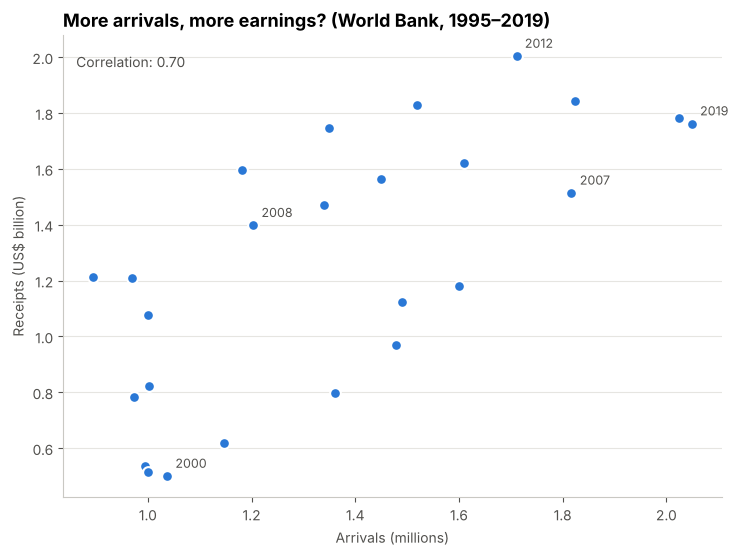

correlation: 0.703


In [6]:
d = arrivals.merge(earnings, on="year").dropna(subset=["wb_arrivals", "wb_receipts_usd"])
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(d["wb_arrivals"]/1e6, d["wb_receipts_usd_bn"], s=60, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
for _, r in d.iterrows():
    if r["year"] in (2000, 2007, 2008, 2012, 2019):
        ax.annotate(int(r["year"]), (r["wb_arrivals"]/1e6, r["wb_receipts_usd_bn"]), xytext=(6, 6),
                    textcoords="offset points", color=MUTED, fontsize=9)
corr = d["wb_arrivals"].corr(d["wb_receipts_usd"])
ax.set_title("More arrivals, more earnings? (World Bank, 1995–2019)")
ax.set_xlabel("Arrivals (millions)"); ax.set_ylabel("Receipts (US$ billion)"); ax.grid(axis="x", visible=False)
ax.text(0.02, 0.96, f"Correlation: {corr:.2f}", transform=ax.transAxes, color=MUTED, va="top")
save("arrivals_vs_earnings")
print("correlation:", round(corr, 3))

### Chart 4: Arrivals by purpose of visit (`visitors_by_purpose.png`)

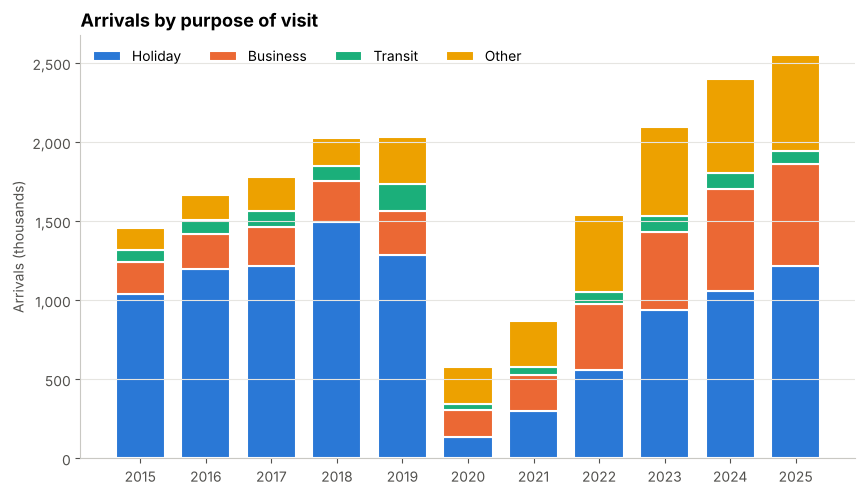

purpose,Holiday,Business,Transit,Other
year,,,,
2019,63.3,13.5,8.5,14.8
2024,44.1,26.8,4.2,24.9
2025,47.8,25.2,3.2,23.7


In [7]:
p = purpose[(purpose.period == "Annual") & (purpose.purpose != "Total")]
pv = p.pivot(index="year", columns="purpose", values="arrivals_thousand")[["Holiday", "Business", "Transit", "Other"]]
fig, ax = plt.subplots(figsize=(10, 5.5))
bottom = None
for col, colr in zip(pv.columns, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.bar(pv.index, pv[col], bottom=bottom, color=colr, edgecolor="white", linewidth=1.5, label=col, width=0.75)
    bottom = pv[col] if bottom is None else bottom + pv[col]
ax.set_title("Arrivals by purpose of visit")
ax.set_ylabel("Arrivals (thousands)"); ax.set_xticks(pv.index)
ax.legend(frameon=False, ncol=4, loc="upper left")
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
save("visitors_by_purpose")
share = (pv.div(pv.sum(axis=1), axis=0) * 100).round(1)
share.loc[[2019, 2024, 2025]]

### Chart 5: Seasonal pattern (`monthly_seasonality.png`)

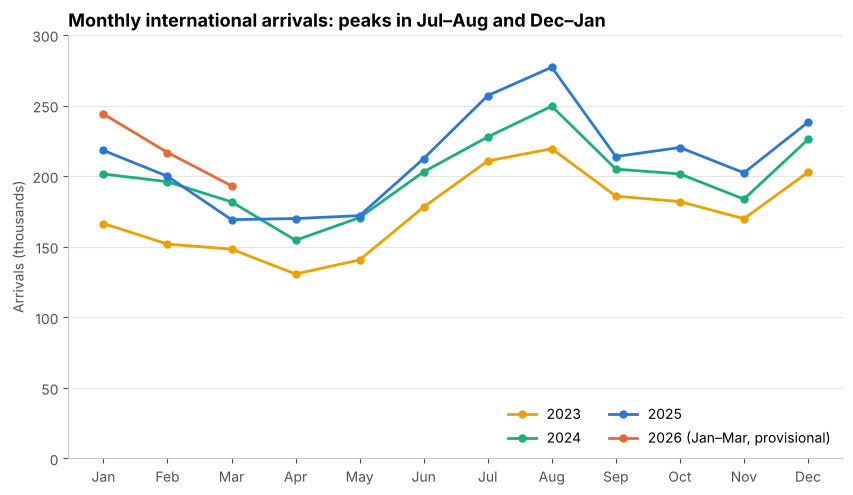

In [8]:
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(figsize=(10, 5.5))
for yr, colr, ls in [(2023, YELLOW, "-"), (2024, AQUA, "-"), (2025, BLUE, "-"), (2026, ORANGE, "-")]:
    m = monthly[monthly.year == yr].copy()
    m["i"] = m["month"].map({k: i for i, k in enumerate(months)})
    m = m.sort_values("i")
    ax.plot(m["i"], m["total"]/1e3, color=colr, lw=2, marker="o", ms=5, label=f"{yr}" + (" (Jan–Mar, provisional)" if yr == 2026 else ""))
ax.set_xticks(range(12)); ax.set_xticklabels(months)
ax.set_title("Monthly international arrivals: peaks in Jul–Aug and Dec–Jan")
ax.set_ylabel("Arrivals (thousands)"); ax.set_ylim(0, 300); ax.legend(frameon=False, ncol=2, loc="lower right")
save("monthly_seasonality")

### Chart 6: Year-on-year growth (`yoy_growth.png`)

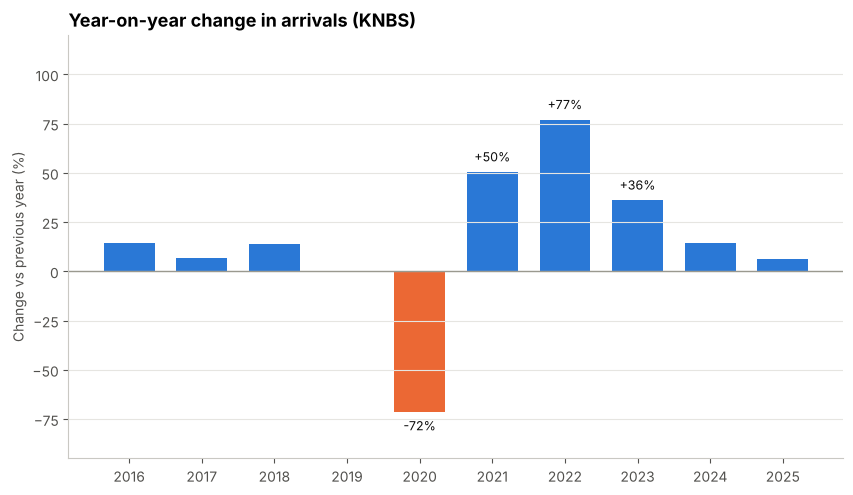

In [9]:
g = arrivals.dropna(subset=["knbs_yoy_pct"])
g = g[g.year >= 2016]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(g["year"], g["knbs_yoy_pct"], color=[BLUE if v >= 0 else ORANGE for v in g["knbs_yoy_pct"]], width=0.7)
ax.axhline(0, color="#9a998f", lw=1)
for _, r in g.iterrows():
    if abs(r["knbs_yoy_pct"]) > 30:
        ax.text(r["year"], r["knbs_yoy_pct"] + (4 if r["knbs_yoy_pct"] > 0 else -3), f'{r["knbs_yoy_pct"]:+.0f}%',
                ha="center", va="bottom" if r["knbs_yoy_pct"] > 0 else "top", color=INK, fontsize=9)
ax.set_title("Year-on-year change in arrivals (KNBS)")
ax.set_ylabel("Change vs previous year (%)"); ax.set_xticks(g["year"]); ax.set_ylim(-95, 120)
save("yoy_growth")

## 4. Findings (calculated from the data)
This cell computes every number from the CSVs and writes the findings, so they update if the data changes.

In [10]:
from IPython.display import Markdown, display

k = arrivals.set_index("year")["knbs_arrivals"]
shares = (pv.div(pv.sum(axis=1), axis=0) * 100)
m25 = monthly[monthly.year == 2025].sort_values("total")
season = monthly[monthly.year.isin([2023, 2024, 2025])].groupby("month")["total"].mean()
high2 = season[["Jul", "Aug"]].mean(); low3 = season[["Mar", "Apr", "May"]].mean()
e = earnings.set_index("year")
corr = arrivals.merge(earnings, on="year").dropna(subset=["wb_arrivals", "wb_receipts_usd"])
corr = corr["wb_arrivals"].corr(corr["wb_receipts_usd"])

f = []
f.append(f"**1. Full recovery.** International arrivals reached **{k[2025]/1e6:.2f} million in 2025**, "
         f"{(k[2025]/k[2024]-1)*100:+.1f}% on 2024 and {(k[2025]/k[2019]-1)*100:+.1f}% above the pre-COVID level of {k[2019]/1e6:.2f} million (2019). "
         f"In 2020 they fell {abs((k[2020]/k[2019]-1)*100):.1f}% to {k[2020]/1e6:.2f} million.")
f.append(f"**2. The visitor mix has shifted.** Holiday visitors made up {shares.loc[2019,'Holiday']:.1f}% of arrivals in 2019 and {shares.loc[2025,'Holiday']:.1f}% in 2025, "
         f"while business rose from {shares.loc[2019,'Business']:.1f}% to {shares.loc[2025,'Business']:.1f}% and 'Other' (including visiting friends and relatives) "
         f"from {shares.loc[2019,'Other']:.1f}% to {shares.loc[2025,'Other']:.1f}%.")
f.append(f"**3. Strong seasonality.** In 2025 arrivals peaked in **{m25.iloc[-1]['month']}** ({m25.iloc[-1]['total']:,.0f}) and were lowest in **{m25.iloc[0]['month']}** ({m25.iloc[0]['total']:,.0f}). "
         f"Across 2023-2025, July-August averages {high2:,.0f} arrivals a month against {low3:,.0f} in March-May ({(high2/low3-1)*100:.0f}% higher).")
f.append(f"**4. Early 2026 is ahead of last year.** January-March 2026 arrivals were "
         f"{monthly[(monthly.year==2026)].total.sum():,.0f}, {(monthly[(monthly.year==2026)].total.sum()/monthly[(monthly.year==2025)&(monthly.month.isin(['Jan','Feb','Mar']))].total.sum()-1)*100:+.1f}% on the same months of 2025 (provisional).")
f.append(f"**5. Earnings are rising fast.** Balance-of-payments travel receipts grew from KSh {e.loc[2021,'bop_travel_receipts_ksh_million']/1e3:,.1f} billion in 2021 to "
         f"KSh {e.loc[2025,'bop_travel_receipts_ksh_million']/1e3:,.1f} billion in 2025 (about US${e.loc[2021,'bop_travel_usd_bn']:.1f} bn to US${e.loc[2025,'bop_travel_usd_bn']:.1f} bn). "
         f"Note: this is a different measure from the World Bank receipts series, which stops in 2019 at US${e.loc[2019,'wb_receipts_usd_bn']:.2f} bn.")
f.append(f"**6. Arrivals and earnings move together, loosely.** Over 1995-2019 the correlation between World Bank arrivals and receipts is **{corr:.2f}**, "
         f"so arrivals explain only part of earnings. Spending per visitor, length of stay and the mix of visitors also matter.")
display(Markdown("\n\n".join(f)))

**1. Full recovery.** International arrivals reached **2.55 million in 2025**, +6.2% on 2024 and +25.3% above the pre-COVID level of 2.04 million (2019). In 2020 they fell 71.5% to 0.58 million.

**2. The visitor mix has shifted.** Holiday visitors made up 63.3% of arrivals in 2019 and 47.8% in 2025, while business rose from 13.5% to 25.2% and 'Other' (including visiting friends and relatives) from 14.8% to 23.7%.

**3. Strong seasonality.** In 2025 arrivals peaked in **Aug** (277,155) and were lowest in **Mar** (169,178). Across 2023-2025, July-August averages 240,292 arrivals a month against 159,757 in March-May (50% higher).

**4. Early 2026 is ahead of last year.** January-March 2026 arrivals were 653,919, +11.3% on the same months of 2025 (provisional).

**5. Earnings are rising fast.** Balance-of-payments travel receipts grew from KSh 141.6 billion in 2021 to KSh 494.7 billion in 2025 (about US$1.3 bn to US$3.8 bn). Note: this is a different measure from the World Bank receipts series, which stops in 2019 at US$1.76 bn.

**6. Arrivals and earnings move together, loosely.** Over 1995-2019 the correlation between World Bank arrivals and receipts is **0.70**, so arrivals explain only part of earnings. Spending per visitor, length of stay and the mix of visitors also matter.

## 5. Limitations
- World Bank has no Kenya data after 2019, so the long series combines different sources.
- World Bank and KNBS arrivals differ in 2015-2019, so they are never joined.
- 2021-2025 earnings are balance-of-payments travel receipts converted to US$ by average exchange rate, which is not the same measure as the World Bank series. 2020 is missing.
- 2025 and 2026 figures are provisional.